
# Pipeline, Tratamento e Engenharia de Dados

## 1. Introdução

Este notebook tem como objetivo apresentar e explicar as etapas de pipeline, tratamento e engenharia de dados desenvolvidas no projeto, demonstrando como os dados são preparados para utilização em modelos de Machine Learning.

O projeto utiliza uma base de chamados de suporte técnico, na qual cada registro representa um chamado que precisa ser analisado e classificado em uma categoria, como Software, Rede, Hardware, RH, Acesso ou Financeiro.

Antes de utilizar esses dados no treinamento de um modelo, é necessário compreender sua estrutura, verificar sua qualidade, padronizar informações e realizar as transformações necessárias.

## 2. Objetivos

- Compreender o fluxo de dados dentro do projeto.
- Identificar as diferenças entre dados brutos, dados tratados e dados preparados para modelagem.
- Explicar as etapas de limpeza, transformação e validação.
- Entender o papel da engenharia de dados na organização e na reprodutibilidade do processo.
- Demonstrar como os dados tratados podem ser utilizados posteriormente em modelos de Machine Learning.

## 3. Organização do estudo

Ao longo deste notebook, serão apresentados conceitos teóricos, trechos de código utilizados no projeto e análises dos resultados obtidos.

O foco será compreender não apenas como cada etapa funciona, mas também por que ela é importante para garantir a qualidade dos dados e apoiar o desenvolvimento de modelos de classificação.


In [1]:

from pathlib import Path
import pandas as pd

# Caminhos dos arquivos em relação à pasta notebooks/
caminho_raw = Path("../data/raw/chamados.csv")
caminho_clean = Path("../data/clean/chamados-clean.csv")

# Carregamento das bases
df_raw = pd.read_csv(caminho_raw)
df_clean = pd.read_csv(caminho_clean)

print("DADOS BRUTOS")
print(f"Quantidade de linhas: {df_raw.shape[0]}")
print(f"Quantidade de colunas: {df_raw.shape[1]}")

print("\nDADOS TRATADOS")
print(f"Quantidade de linhas: {df_clean.shape[0]}")
print(f"Quantidade de colunas: {df_clean.shape[1]}")

DADOS BRUTOS
Quantidade de linhas: 5000
Quantidade de colunas: 44

DADOS TRATADOS
Quantidade de linhas: 5000
Quantidade de colunas: 44


### 4. Comparação inicial entre os dados brutos e tratados

A primeira etapa consiste em comparar as dimensões da base original com as da base tratada. Essa análise permite verificar se houve alterações na quantidade de registros ou atributos durante o processo de tratamento.

Observa-se que as duas bases possuem a mesma quantidade de linhas e colunas. Portanto, nesta comparação inicial, não houve redução no número de registros nem de atributos.

Entretanto, a igualdade das dimensões não garante que os dados estejam idênticos. O tratamento pode ter envolvido operações como padronização de textos, normalização de nomes de colunas ou ajustes em valores. Por isso, é necessário realizar análises adicionais para identificar as transformações efetivamente realizadas.


In [2]:

# Comparar os nomes das colunas das duas bases
print("As colunas são iguais?")
print(df_raw.columns.equals(df_clean.columns))

print("\nColunas presentes nos dados brutos:")
print(df_raw.columns.tolist())

print("\nColunas presentes nos dados tratados:")
print(df_clean.columns.tolist())

# Comparar os tipos de dados
comparacao_tipos = pd.DataFrame({
    "Tipo bruto": df_raw.dtypes.astype(str),
    "Tipo tratado": df_clean.dtypes.astype(str)
})

print("\nComparação dos tipos de dados:")
display(comparacao_tipos)

# Comparar a quantidade de valores ausentes
comparacao_nulos = pd.DataFrame({
    "Nulos brutos": df_raw.isnull().sum(),
    "Nulos tratados": df_clean.isnull().sum()
})

print("\nComparação de valores ausentes:")
display(comparacao_nulos)

As colunas são iguais?
True

Colunas presentes nos dados brutos:
['ticket_id', 'created_at', 'customer_id', 'department', 'city_x', 'state_x', 'device_type', 'os', 'browser', 'network_type', 'historical_tickets', 'sla_hours', 'resolution_time_hours', 'title', 'description', 'image_path', 'image_width', 'image_height', 'priority', 'status', 'assigned_team', 'has_attachment', 'sentiment_score', 'num_words', 'num_images_x', 'latitude', 'longitude', 'company', 'segment', 'employees', 'city_y', 'state_y', 'contract_type', 'customer_since', 'vip', 'monthly_revenue', 'num_events', 'last_event_date', 'event_types', 'num_abertura', 'num_updates', 'num_encerramento', 'num_images_y', 'target_category']

Colunas presentes nos dados tratados:
['ticket_id', 'created_at', 'customer_id', 'department', 'city_x', 'state_x', 'device_type', 'os', 'browser', 'network_type', 'historical_tickets', 'sla_hours', 'resolution_time_hours', 'title', 'description', 'image_path', 'image_width', 'image_height', 'prio

,Tipo bruto,Tipo tratado
ticket_id,int64,int64
created_at,object,object
customer_id,int64,int64
department,object,object
city_x,object,object
state_x,object,object
device_type,object,object
os,object,object
browser,object,object
network_type,object,object



Comparação de valores ausentes:


,Nulos brutos,Nulos tratados
ticket_id,0,0
created_at,0,0
customer_id,0,0
department,0,0
city_x,0,0
state_x,0,0
device_type,0,0
os,0,0
browser,0,0
network_type,0,0


### 5. Análise da qualidade dos dados

A comparação entre as bases bruta e tratada apresentou os seguintes resultados:

- **Estrutura:** as duas bases possuem 5.000 registros e 44 colunas.
- **Atributos:** os nomes e a ordem das colunas são iguais.
- **Tipos de dados:** não foram identificadas diferenças nos tipos das colunas.
- **Valores ausentes:** a quantidade de valores nulos permaneceu igual em todos os atributos analisados.

Apesar da consistência estrutural, foram identificados atributos com grande quantidade de informações ausentes. As colunas `company`, `segment`, `employees`, `city_y`, `state_y`, `contract_type`, `customer_since`, `vip` e `monthly_revenue` possuem 4.998 valores ausentes. Além disso, `last_event_date`, `event_types` e `num_images_y` não apresentam nenhum valor preenchido.

Esses resultados indicam a necessidade de uma análise adicional para determinar quais atributos são úteis para a classificação dos chamados e quais medidas devem ser adotadas em relação aos valores ausentes.

É importante destacar que a comparação estrutural, isoladamente, não permite concluir se os conteúdos das bases são idênticos.


In [3]:

# Comparar os valores de cada coluna entre as duas bases
diferencas = []

for coluna in df_raw.columns:
    valores_raw = df_raw[coluna].astype("string").fillna("<VALOR_NULO>")
    valores_clean = df_clean[coluna].astype("string").fillna("<VALOR_NULO>")

    quantidade_diferencas = (valores_raw != valores_clean).sum()

    diferencas.append({
        "Coluna": coluna,
        "Valores diferentes": int(quantidade_diferencas)
    })

df_diferencas = pd.DataFrame(diferencas)

print("Quantidade total de valores diferentes:")
print(df_diferencas["Valores diferentes"].sum())

print("\nColunas que apresentam diferenças:")
display(
    df_diferencas[
        df_diferencas["Valores diferentes"] > 0
    ].sort_values("Valores diferentes", ascending=False)
)


Quantidade total de valores diferentes:
0

Colunas que apresentam diferenças:


,Coluna,Valores diferentes


In [4]:

from pathlib import Path

caminho_cleaner = Path("../src/data/cleaner.py")

print(caminho_cleaner.read_text(encoding="utf-8"))


"""
cleaner.py
----------
Lógica de limpeza genérica aplicada a qualquer DataFrame da pipeline.

Obs: Adicionar novas funções de limpeza se precisar ao longo do projeto.
"""

import re
import sys
import unicodedata
from pathlib import Path

import pandas as pd

ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(ROOT))

from src.config import PATHS

RAW_DIR     = PATHS.data_raw
CLEAN_DIR   = PATHS.data_clean

encodings = ["utf-8", "utf-8-sig", "latin1", "iso-8859-1", "cp1252"]
na_values = ['nan', '?', 'null', 'none']
separators = [";", ","]

def has_replacement_char(df: pd.DataFrame) -> bool:
    return any("�" in str(col) for col in df.columns)

def careful_load_csv(path: Path, sep: str | None = None) -> pd.DataFrame:
    errors = []

    for encoding in encodings:
        for separator in separators:
            try:
                df = pd.read_csv(path, sep=separator, encoding=encoding, low_memory=False, na_values=na_values)

                if len(df.columns) <= 1:
 

In [5]:

import sys

# Adiciona a raiz do projeto ao caminho de importação
sys.path.insert(0, str(Path.cwd().parent.resolve()))

from src.data.cleaner import clean_dataframe

# Executa a limpeza sobre uma cópia dos dados brutos
df_teste_cleaner = clean_dataframe(df_raw.copy())

print("Dimensões após executar o cleaner:")
print(df_teste_cleaner.shape)

# Compara o resultado da execução com o arquivo tratado
print("\nO resultado do cleaner é igual ao arquivo tratado?")
print(df_teste_cleaner.equals(df_clean))

# Compara a quantidade de valores diferentes em relação à base bruta
print("\nQuantidade de valores diferentes após a limpeza:")
print(
    df_raw.astype("string").fillna("<NULO>")
    .compare(
        df_teste_cleaner.astype("string").fillna("<NULO>")
    ).shape[0]
)


C:\Users\Pichau\ProjetoIntegrador-II\src\data\cleaner.py:133: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed_dates = pd.to_datetime(series, errors="coerce")
C:\Users\Pichau\ProjetoIntegrador-II\src\data\cleaner.py:133: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed_dates = pd.to_datetime(series, errors="coerce")
C:\Users\Pichau\ProjetoIntegrador-II\src\data\cleaner.py:133: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed_dates = pd.to_datetime(series, errors="coerce")
C:\Users\Pichau\ProjetoIntegrador-II\src\data\cleaner.py:133: UserWarning: Could not infer 

Dimensões após executar o cleaner:
(5000, 44)

O resultado do cleaner é igual ao arquivo tratado?
False

Quantidade de valores diferentes após a limpeza:
5000


C:\Users\Pichau\ProjetoIntegrador-II\src\data\cleaner.py:133: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed_dates = pd.to_datetime(series, errors="coerce")


In [6]:

# Comparar os tipos de dados antes e depois da limpeza
comparacao = pd.DataFrame({
    "Tipo original": df_raw.dtypes.astype(str),
    "Tipo após cleaner": df_teste_cleaner.dtypes.astype(str),
    "Valores diferentes": [
        (
            df_raw[col].astype("string").fillna("<NULO>") !=
            df_teste_cleaner[col].astype("string").fillna("<NULO>")
        ).sum()
        for col in df_raw.columns
    ]
})

# Exibir somente as colunas que apresentaram diferenças
display(
    comparacao[comparacao["Valores diferentes"] > 0]
    .sort_values("Valores diferentes", ascending=False)
)


,Tipo original,Tipo após cleaner,Valores diferentes
created_at,object,datetime64[ns],5000


### 6. Transformação dos dados com a rotina de limpeza

Após executar diretamente a função `clean_dataframe()`, foi identificada uma transformação na coluna `created_at`.

Originalmente, essa coluna estava armazenada como texto (`object`). Durante o processo de limpeza, o Pandas reconheceu seus valores como datas e realizou a conversão para `datetime64[ns]`.

Essa transformação é realizada pela função `pd.to_datetime()`, que permite interpretar valores textuais como datas e horários.

A conversão é importante porque possibilita operações temporais, como extração de ano e mês, ordenação cronológica e cálculo de intervalos entre eventos.

O teste também demonstrou que a rotina de limpeza manteve as dimensões da base em 5.000 linhas e 44 colunas.

Portanto, mesmo sem remover registros ou atributos, o processo de limpeza pode melhorar a estrutura dos dados e facilitar sua utilização nas etapas posteriores de análise e Machine Learning.


In [7]:

print("Tipo original:", df_raw["created_at"].dtype)
print("Tipo após limpeza:", df_teste_cleaner["created_at"].dtype)

print("\nValores ausentes antes:", df_raw["created_at"].isna().sum())
print("Valores ausentes depois:", df_teste_cleaner["created_at"].isna().sum())

print("\nExemplos de datas originais:")
display(df_raw["created_at"].head())

print("\nExemplos de datas após conversão:")
display(df_teste_cleaner["created_at"].head())


Tipo original: object
Tipo após limpeza: datetime64[ns]

Valores ausentes antes: 0
Valores ausentes depois: 0

Exemplos de datas originais:


0    2025-01-01T00:17:00
1    2025-01-01T00:34:00
2    2025-01-01T00:51:00
3    2025-01-01T01:08:00
4    2025-01-01T01:25:00
Name: created_at, dtype: object


Exemplos de datas após conversão:


0   2025-01-01 00:17:00
1   2025-01-01 00:34:00
2   2025-01-01 00:51:00
3   2025-01-01 01:08:00
4   2025-01-01 01:25:00
Name: created_at, dtype: datetime64[ns]

In [8]:

caminho_processor = Path("../src/data/processor.py")

print(caminho_processor.read_text(encoding="utf-8"))


"""
processor.py
------------
Funções de processamento pro dataset, primeiro carrega a configuração do sources.yaml,
depois aplica as transformações, valida a qualidade e finalmente salva o resultado em parquet.
"""
from pathlib import Path

import pandas as pd
import yaml

from src.config import PATHS
from src.data.validator import validate_quality

def project_path(value: str | Path, root: Path = PATHS.root) -> Path:
    path = Path(value)

    return (path if path.is_absolute() else root / path).resolve()

def load_yaml(path: Path) -> dict:
    with path.open(encoding="utf-8") as stream:
        config = yaml.safe_load(stream)

    if not isinstance(config, dict):
        raise ValueError(f"Configuração vazia ou inválida: {path}")
    
    return config

def require_columns(df: pd.DataFrame, columns: list[str], context: str) -> None:
    missing = [column for column in columns if column not in df.columns]
    if missing:
        raise ValueError(f"{context}: colunas ausentes: {missi

In [10]:

linhas_processor = caminho_processor.read_text(encoding="utf-8").splitlines()

print(f"Total de linhas: {len(linhas_processor)}")

# Exibir as linhas 1 a 100
for numero, linha in enumerate(linhas_processor[:100], start=1):
    print(f"{numero:03}: {linha}")


Total de linhas: 176
001: """
002: processor.py
003: ------------
004: Funções de processamento pro dataset, primeiro carrega a configuração do sources.yaml,
005: depois aplica as transformações, valida a qualidade e finalmente salva o resultado em parquet.
006: """
007: from pathlib import Path
008: 
009: import pandas as pd
010: import yaml
011: 
012: from src.config import PATHS
013: from src.data.validator import validate_quality
014: 
015: def project_path(value: str | Path, root: Path = PATHS.root) -> Path:
016:     path = Path(value)
017: 
018:     return (path if path.is_absolute() else root / path).resolve()
019: 
020: def load_yaml(path: Path) -> dict:
021:     with path.open(encoding="utf-8") as stream:
022:         config = yaml.safe_load(stream)
023: 
024:     if not isinstance(config, dict):
025:         raise ValueError(f"Configuração vazia ou inválida: {path}")
026:     
027:     return config
028: 
029: def require_columns(df: pd.DataFrame, columns: list[str], context:

### 7. Processamento e transformação dos dados

Após a etapa de limpeza, o projeto possui um módulo específico para o processamento estruturado dos dados: o `processor.py`.

Diferentemente da limpeza genérica, esse módulo utiliza configurações externas definidas em um arquivo YAML para determinar quais transformações devem ser aplicadas.

O processamento contempla:

1. **Carregamento:** leitura das configurações e dos dados de entrada.
2. **Conversão de tipos:** padronização de atributos textuais, numéricos, categóricos, booleanos e temporais.
3. **Seleção de atributos:** remoção das colunas definidas na configuração.
4. **Validação:** verificação da qualidade dos dados conforme regras estabelecidas.
5. **Armazenamento:** persistência do resultado em formato Parquet.

Essa separação entre código e configuração facilita a manutenção e permite adaptar o processamento sem precisar alterar diretamente as funções Python.

O resultado dessa etapa é uma base processada, com tipos de dados definidos e submetida às regras de qualidade, que poderá ser utilizada nas etapas seguintes da pipeline.

É importante observar que o processamento configurado não representa, por si só, o treinamento de um modelo de Machine Learning. Ele prepara e organiza os dados para essa finalidade.


In [11]:

caminho_sources = Path("../src/config/sources.yaml")

print(caminho_sources.read_text(encoding="utf-8"))


# =============================================================================
# Configuração de Dados
# =============================================================================
dataset:
  entrada: data/clean/chamados-clean.csv
  saida: data/processed/chamados.parquet
  leitura:
    sep: ','
    encoding: utf-8-sig

# Tipos: string | Int64 | Float64 | boolean | datetime | category
# errors: raise interrompe em valores inválidos enquanto coerce transforma em nulos.
transformacoes:
  ticket_id: {cast: string}
  sla_hours: {cast: Float64}
  resolution_time_hours: {cast: Float64}
  sentiment_score: {cast: Float64}  # Valor original; PLN substitui só no dataset enriquecido.
  num_words: {cast: Float64}
  image_path: {cast: string}
  title: {cast: string}
  description: {cast: string}
  target_category: {cast: string}

qualidade:
  relatorio: reports/data/quality.json
  cols_obrigatorias: [ticket_id, target_category, title, description, image_path, sla_hours, sentiment_score, num_words

### 7.1. Configuração do processamento com YAML

O comportamento do módulo `processor.py` é definido por meio do arquivo `sources.yaml`, que centraliza as configurações necessárias para o processamento dos dados.

Essa abordagem permite separar as regras de processamento da implementação em Python, facilitando a manutenção e a alteração das configurações.

O arquivo define três aspectos principais:

- **Entrada e saída:** especifica o arquivo CSV que será processado e o destino do resultado em formato Parquet.
- **Transformações:** estabelece os tipos de dados esperados para determinadas colunas, como textos, números decimais e identificadores.
- **Remoção de atributos:** define quais colunas não deverão fazer parte da base processada.

Além disso, o arquivo indica o caminho destinado ao relatório de qualidade, gerado durante a etapa de validação.

A utilização dessa configuração contribui para a organização e a reprodutibilidade da pipeline, pois mantém as regras de processamento centralizadas em um único local.

In [13]:
caminho_processed = Path("../data/processed/chamados.parquet")

if caminho_processed.exists():
    df_processed = pd.read_parquet(caminho_processed)

    print("BASE PROCESSADA")
    print(f"Linhas: {df_processed.shape[0]}")
    print(f"Colunas: {df_processed.shape[1]}")

    print("\nTipos de dados:")
    display(df_processed.dtypes.to_frame("Tipo"))

    print("\nPrimeiras linhas:")
    display(df_processed.head())
else:
    print("O arquivo Parquet ainda não foi encontrado.")

BASE PROCESSADA
Linhas: 5000
Colunas: 19

Tipos de dados:


,Tipo
ticket_id,string[python]
department,object
device_type,object
os,object
network_type,object
sla_hours,Float64
resolution_time_hours,Float64
title,string[python]
description,string[python]
image_path,string[python]



Primeiras linhas:


,ticket_id,department,device_type,os,network_type,sla_hours,resolution_time_hours,title,description,image_path,image_width,image_height,priority,status,assigned_team,sentiment_score,num_words,num_images_x,target_category
0,1,Operações,Desktop,Windows,WiFi,4.0,28.0,Falha crítica no teclado: não funciona com tel...,Falha crítica no teclado: não funciona com tel...,images/keyboard.png,500,375,Alta,Fechado,N2,-0.559,6.0,2,Hardware
1,2,Financeiro,Notebook,Windows,5G,12.0,45.0,Falha no sistema de folha ao tentar gerar rela...,Falha no sistema de folha ao tentar gerar rela...,images/payroll.png,612,408,Crítica,Fechado,Aplicações,0.946,6.0,3,RH
2,3,TI,Desktop,Linux,5G,24.0,47.0,O Sistema de tesouraria exibe cheiro de queima...,O Sistema de tesouraria exibe cheiro de queima...,images/finance_report.png,738,414,Média,Em andamento,N2,0.404,6.0,0,Financeiro
3,4,Financeiro,Mobile,Android,Cabo,12.0,52.0,O aplicativo Sistema ERP fecha inesperadamente...,O aplicativo Sistema ERP fecha inesperadamente...,images/sap_erp.png,612,344,Crítica,Aberto,Infra,0.311,3.0,3,Software
4,5,Financeiro,Mobile,iOS,Cabo,48.0,64.0,O acesso à banco de dados falha com reinicia s...,O acesso à banco de dados falha com reinicia s...,images/server.png,500,333,Média,Aberto,N2,0.584,6.0,3,Rede


### Resultado do processamento dos dados

Após a execução do pipeline, os dados foram processados e armazenados no formato Parquet (`chamados.parquet`).

A base resultante possui **5.000 registros e 19 colunas**, representando uma redução em relação à base original, que possuía 44 colunas. Essa redução ocorreu devido à remoção dos campos definidos na configuração `drop_cols` do arquivo `sources.yaml`.

Durante o processamento, também foram aplicadas conversões de tipos de dados, como a padronização de identificadores e campos textuais para `string` e de variáveis numéricas para `Float64`.

A validação de qualidade foi executada pelo `validator.py`, verificando requisitos como colunas obrigatórias, valores nulos, unicidade dos identificadores, intervalos numéricos, categorias permitidas e integridade dos caminhos das imagens.

Por fim, a leitura do arquivo Parquet no notebook confirmou que o processamento foi concluído e que os dados estão disponíveis para as próximas etapas do projeto.

In [14]:
import json
from pathlib import Path

caminho_split = Path("../data/processed/splits/chamados.json")

with open(caminho_split, "r", encoding="utf-8") as arquivo:
    split_data = json.load(arquivo)

print("ESTRUTURA DO ARQUIVO DE DIVISÃO")
print("Tipo:", type(split_data))

if isinstance(split_data, dict):
    print("\nChaves encontradas:")
    for chave, valor in split_data.items():
        if isinstance(valor, list):
            print(f"{chave}: lista com {len(valor)} elementos")
        elif isinstance(valor, dict):
            print(f"{chave}: dicionário com {len(valor)} elementos")
        else:
            print(f"{chave}: {type(valor).__name__} = {valor}")
else:
    print("\nConteúdo inicial:")
    print(str(split_data)[:1000])

ESTRUTURA DO ARQUIVO DE DIVISÃO
Tipo: <class 'dict'>

Chaves encontradas:
format_version: int = 1
created_at: str = 2026-10-30T22:42:21.450437+00:00
dataset_sha256: str = 3130fd77fc82981ef0c08565a6b3c74e7504d1d231cbed6a713cc07b138abe3e
configuration: dicionário com 17 elementos
summary: dicionário com 3 elementos
overlap: dicionário com 1 elementos
warnings: lista com 0 elementos
assignments: lista com 5000 elementos
assignments_sha256: str = a7b73cba6180fcfe5734fc75faa116d63e3535f9c9eee6bd15d59506b3c827f3


In [15]:
print("RESUMO DA DIVISÃO")
display(split_data["summary"])

print("\nCONFIGURAÇÃO UTILIZADA")
display(split_data["configuration"])

print("\nINFORMAÇÕES DE SOBREPOSIÇÃO")
display(split_data["overlap"])

print("\nPRIMEIRAS 5 ATRIBUIÇÕES")
for item in split_data["assignments"][:5]:
    print(item)

RESUMO DA DIVISÃO


{'train': {'rows': 3505,
  'fraction': 0.701,
  'classes': {'Financeiro': 678,
   'Rede': 670,
   'Software': 640,
   'RH': 632,
   'Acesso': 470,
   'Hardware': 415},
  'groups': 18},
 'validation': {'rows': 737,
  'fraction': 0.1474,
  'classes': {'Hardware': 277,
   'Software': 236,
   'RH': 97,
   'Acesso': 46,
   'Financeiro': 42,
   'Rede': 39},
  'groups': 4},
 'test': {'rows': 758,
  'fraction': 0.1516,
  'classes': {'Acesso': 305,
   'Rede': 152,
   'Hardware': 143,
   'RH': 92,
   'Financeiro': 50,
   'Software': 16},
  'groups': 4}}


CONFIGURAÇÃO UTILIZADA


{'target_col': 'target_category',
 'strategy': 'group',
 'id_column': 'ticket_id',
 'train_size': 0.7,
 'validation_size': 0.15,
 'test_size': 0.15,
 'seed': 42,
 'group_column': 'image_path',
 'group_mode': 'image_hash',
 'group_candidates': 512,
 'max_size_deviation': 0.1,
 'time_column': 'created_at',
 'require_all_classes': True,
 'audit_columns': [],
 'overlap_policy': 'warn',
 'image_column': 'image_path',
 'image_base_dir': 'data'}


INFORMAÇÕES DE SOBREPOSIÇÃO


{'image_content_sha256': {'train__validation': 0,
  'train__test': 0,
  'validation__test': 0}}


PRIMEIRAS 5 ATRIBUIÇÕES
{'id': '1', 'split': 'validation'}
{'id': '10', 'split': 'train'}
{'id': '100', 'split': 'train'}
{'id': '1000', 'split': 'validation'}
{'id': '1001', 'split': 'train'}


In [16]:
import hashlib
from pathlib import Path
import pandas as pd

# Criar uma cópia para auditoria
df_auditoria = df_processed.copy()

# Padronizar identificadores
df_auditoria["ticket_id"] = df_auditoria["ticket_id"].astype(str)

# Recuperar a divisão registrada no JSON
mapa_split = {
    item["id"]: item["split"]
    for item in split_data["assignments"]
}

df_auditoria["split"] = df_auditoria["ticket_id"].map(mapa_split)

# Calcular o hash do conteúdo de cada imagem
diretorio_imagens = Path("../data")

def calcular_hash(caminho):
    arquivo = diretorio_imagens / str(caminho)
    return hashlib.sha256(arquivo.read_bytes()).hexdigest()

df_auditoria["image_hash"] = df_auditoria["image_path"].apply(calcular_hash)

# Resumir os grupos
grupos = (
    df_auditoria
    .groupby(["image_hash", "split"])
    .agg(
        quantidade_chamados=("ticket_id", "count"),
        imagem=("image_path", "first"),
        categorias=("target_category", "nunique")
    )
    .reset_index()
    .sort_values("quantidade_chamados", ascending=False)
)

print("TOTAL DE GRUPOS:", df_auditoria["image_hash"].nunique())
print("\nDISTRIBUIÇÃO DOS GRUPOS:")
display(grupos)

print("\nDISTRIBUIÇÃO DAS CATEGORIAS POR GRUPO:")
display(
    pd.crosstab(
        [df_auditoria["image_hash"], df_auditoria["split"]],
        df_auditoria["target_category"]
    )
)

TOTAL DE GRUPOS: 26

DISTRIBUIÇÃO DOS GRUPOS:


,image_hash,split,quantidade_chamados,imagem,categorias
7,40d7e994a67339fba798c15117d4af9eb13616183814f1...,train,755,images/finance_report.png,5
2,231c675d8c814fd285b29939af6fd92bcba769ab52fa20...,test,482,images/login.png,5
6,3d7ff9d021f7974dab0ff0e4cd1461b37d5063bf4dd39b...,train,446,images/network.png,2
3,25afa49ebd699ae7001e94e6e671e71dd316d403b677a6...,validation,355,images/email.png,5
22,d9c370d4c8638991cc6c6bfc1917704b5dc4c09f46d3cb...,train,288,images/sap_erp.png,2
10,561a928fbcf2336af41bcbe181f40cd398ab5c65cc2d36...,train,243,images/browser.png,1
21,d7d4c1bb2452bcac7a7c869bf3147b08b9e66d7479427f...,train,219,images/default_hr.png,1
8,4570b03e21e1b21f9d7351b886f96768259c821b1a56a2...,train,210,images/payroll.png,2
1,15eeb78955bd27382806c8f85ed5df9b0481757411209b...,validation,207,images/default_hardware.png,1
0,10ceffbcbe9663e12a42eae3462a5a305a91a7616421d4...,train,193,images/default_network.png,1



DISTRIBUIÇÃO DAS CATEGORIAS POR GRUPO:


,target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
image_hash,split,,,,,,
10ceffbcbe9663e12a42eae3462a5a305a91a7616421d427d6d545f11aa6e86a,train,0,0,0,0,193,0
15eeb78955bd27382806c8f85ed5df9b0481757411209b249c13b49671dba30b,validation,0,0,207,0,0,0
231c675d8c814fd285b29939af6fd92bcba769ab52fa201b16412e04c6fa4052,test,305,50,0,92,19,16
25afa49ebd699ae7001e94e6e671e71dd316d403b677a6faf27cb1bab00168f1,validation,46,42,0,97,39,131
2abbf88d85c96272462c4d0e13cd7737f277153de7512be011af2a5924227428,train,37,0,0,86,0,0
397453377a8779de69892b65247fde629bf588fc98d09044570ef72b756081d5,train,0,0,67,0,0,0
3d7ff9d021f7974dab0ff0e4cd1461b37d5063bf4dd39bbeb2d4d9033d0c5361,train,0,0,7,0,439,0
40d7e994a67339fba798c15117d4af9eb13616183814f1c9a96c97c1366b0367,train,37,541,0,97,38,42
4570b03e21e1b21f9d7351b886f96768259c821b1a56a28ee03c0696771bc056,train,56,0,0,154,0,0


In [17]:
# Verificar as dimensões do dataset
print(f"Quantidade de registros: {df_processed.shape[0]}")
print(f"Quantidade de colunas: {df_processed.shape[1]}")

# Visualizar as colunas disponíveis
display(pd.DataFrame({
    "Coluna": df_processed.columns,
    "Tipo de dado": df_processed.dtypes.astype(str).values,
    "Valores ausentes": df_processed.isnull().sum().values,
    "Valores únicos": df_processed.nunique().values
}))

Quantidade de registros: 5000
Quantidade de colunas: 19


,Coluna,Tipo de dado,Valores ausentes,Valores únicos
0,ticket_id,string,0,5000
1,department,object,0,4
2,device_type,object,0,3
3,os,object,0,4
4,network_type,object,0,4
5,sla_hours,Float64,0,5
6,resolution_time_hours,Float64,0,72
7,title,string,0,2519
8,description,string,0,2564
9,image_path,string,0,26


In [18]:
# Contagem de chamados por categoria
contagem_categorias = df_processed["target_category"].value_counts()

# Percentual de cada categoria
percentual_categorias = (
    df_processed["target_category"]
    .value_counts(normalize=True) * 100
)

# Criar tabela de distribuição
distribuicao_categorias = pd.DataFrame({
    "Quantidade": contagem_categorias,
    "Percentual (%)": percentual_categorias.round(2)
})

display(distribuicao_categorias)

,Quantidade,Percentual (%)
target_category,,
Software,892,17.84
Rede,861,17.22
Hardware,835,16.7
RH,821,16.42
Acesso,821,16.42
Financeiro,770,15.4


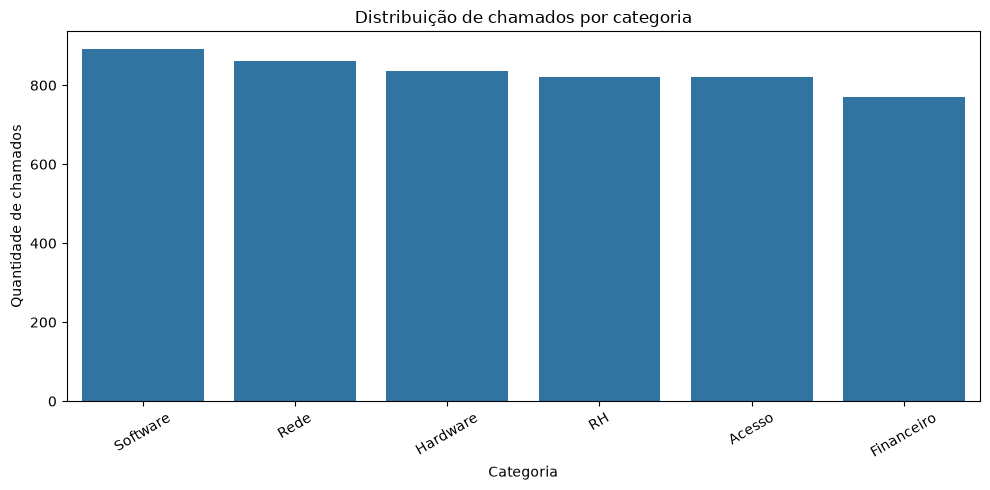

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_processed,
    x="target_category",
    order=df_processed["target_category"].value_counts().index
)

plt.title("Distribuição de chamados por categoria")
plt.xlabel("Categoria")
plt.ylabel("Quantidade de chamados")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Distribuição das categorias de chamados

A análise da variável `target_category` demonstrou uma distribuição relativamente equilibrada entre as seis categorias existentes no dataset.

A categoria Software apresenta a maior quantidade de registros, com 892 chamados (17,84%), enquanto Financeiro possui a menor quantidade, com 770 chamados (15,40%).

A diferença relativamente pequena entre as categorias indica que o dataset não apresenta um desequilíbrio expressivo de classes (*class imbalance*).

Essa característica é favorável para o desenvolvimento dos modelos de classificação, pois reduz a possibilidade de uma categoria dominar o processo de treinamento simplesmente por possuir uma quantidade muito superior de registros.

In [20]:
# Criar tabela de distribuição por conjunto
distribuicao_split = pd.crosstab(
    df_auditoria["split"],
    df_auditoria["target_category"]
)

display(distribuicao_split)

target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
split,,,,,,
test,305,50,143,92,152,16
train,470,678,415,632,670,640
validation,46,42,277,97,39,236


<Figure size 1100x500 with 0 Axes>

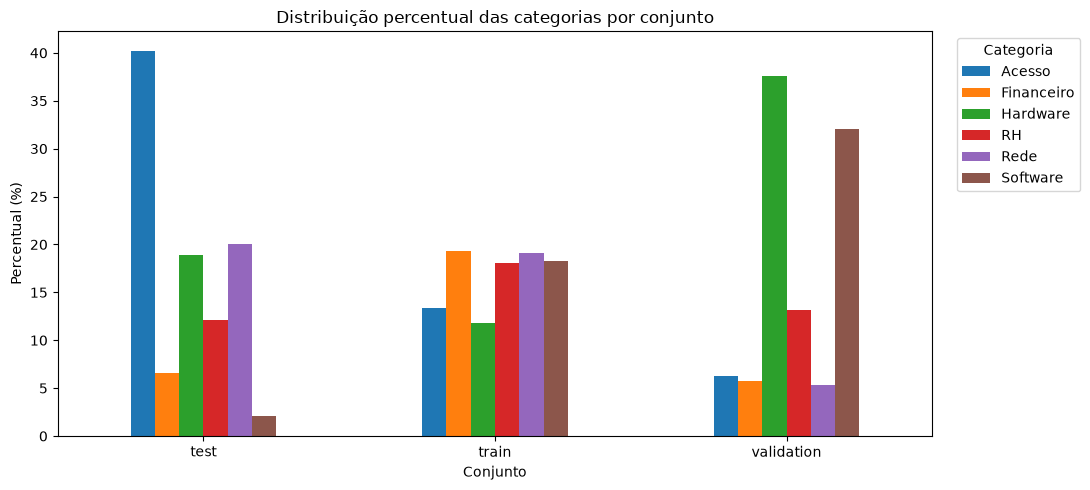

In [21]:
# Calcular distribuição percentual por conjunto
distribuicao_percentual = pd.crosstab(
    df_auditoria["split"],
    df_auditoria["target_category"],
    normalize="index"
) * 100

plt.figure(figsize=(11, 5))

distribuicao_percentual.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Distribuição percentual das categorias por conjunto")
plt.xlabel("Conjunto")
plt.ylabel("Percentual (%)")
plt.xticks(rotation=0)
plt.legend(title="Categoria", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Análise da distribuição das categorias entre os conjuntos

Após a divisão do dataset em treinamento, validação e teste, foi realizada uma análise da distribuição das categorias em cada conjunto.

Embora o dataset original apresente uma distribuição relativamente equilibrada entre as seis categorias, essa característica não foi preservada integralmente durante a divisão por grupos de imagens.

Foram identificadas concentrações de determinadas categorias em conjuntos específicos. Por exemplo, Hardware representa aproximadamente 37,58% dos registros de validação, enquanto Acesso corresponde a aproximadamente 40,24% dos registros de teste.

Também foi observado que a categoria Software possui apenas 16 registros no conjunto de teste.

Esse comportamento está relacionado à estratégia de agrupamento por hash das imagens, que mantém chamados associados à mesma imagem no mesmo conjunto.

Portanto, a distribuição obtida apresenta limitações que devem ser consideradas durante a avaliação dos modelos, especialmente na interpretação das métricas individuais por categoria.

In [22]:
# Contagem de chamados por prioridade
distribuicao_prioridade = df_processed["priority"].value_counts()

# Percentual por prioridade
percentual_prioridade = (
    df_processed["priority"].value_counts(normalize=True) * 100
)

# Tabela de distribuição
tabela_prioridade = pd.DataFrame({
    "Quantidade": distribuicao_prioridade,
    "Percentual (%)": percentual_prioridade.round(2)
})

display(tabela_prioridade)

,Quantidade,Percentual (%)
priority,,
Crítica,1277,25.54
Baixa,1260,25.20
Média,1248,24.96
Alta,1215,24.30


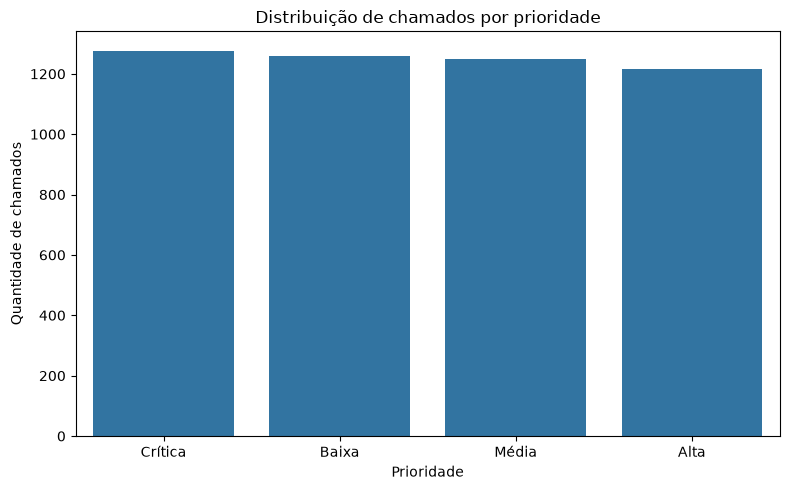

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_processed,
    x="priority",
    order=df_processed["priority"].value_counts().index
)

plt.title("Distribuição de chamados por prioridade")
plt.xlabel("Prioridade")
plt.ylabel("Quantidade de chamados")

plt.tight_layout()
plt.show()

### Distribuição dos chamados por prioridade

Foi analisada a distribuição da variável `priority`, que representa o nível de prioridade atribuído aos chamados.

Os resultados demonstraram uma distribuição equilibrada entre as quatro classificações existentes: Crítica (25,54%), Baixa (25,20%), Média (24,96%) e Alta (24,30%).

A diferença entre a prioridade mais frequente e a menos frequente é de apenas 62 registros, indicando que não existe concentração expressiva em uma única categoria.

Essa característica permite compreender melhor o perfil dos chamados e oferece uma visão geral da composição do dataset em relação à urgência dos atendimentos.

In [24]:
# Contagem de chamados por departamento
distribuicao_departamento = df_processed["department"].value_counts()

# Percentual por departamento
percentual_departamento = (
    df_processed["department"].value_counts(normalize=True) * 100
)

# Criar tabela
tabela_departamento = pd.DataFrame({
    "Quantidade": distribuicao_departamento,
    "Percentual (%)": percentual_departamento.round(2)
})

display(tabela_departamento)

,Quantidade,Percentual (%)
department,,
RH,1274,25.48
TI,1273,25.46
Operações,1229,24.58
Financeiro,1224,24.48


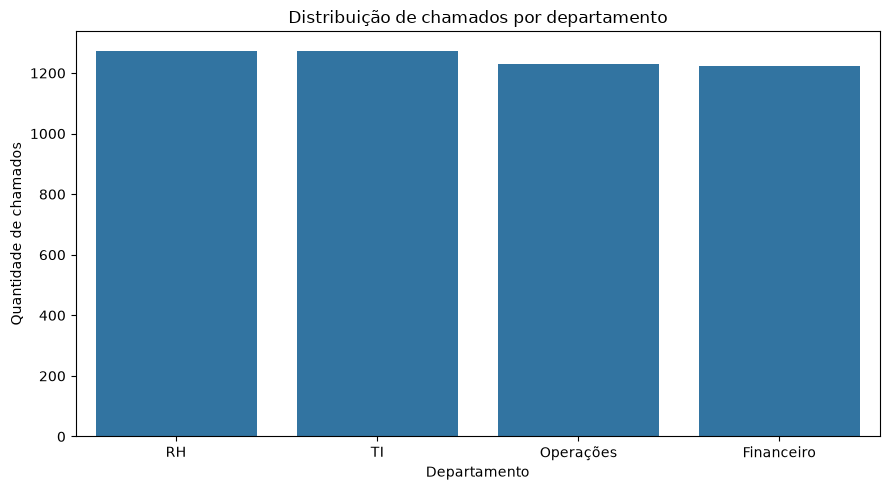

In [25]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_processed,
    x="department",
    order=df_processed["department"].value_counts().index
)

plt.title("Distribuição de chamados por departamento")
plt.xlabel("Departamento")
plt.ylabel("Quantidade de chamados")

plt.tight_layout()
plt.show()

### Distribuição dos chamados por departamento

A análise da variável `department` demonstrou uma distribuição equilibrada entre os quatro departamentos presentes no dataset.

O departamento de RH apresenta a maior quantidade de registros, com 1.274 chamados (25,48%), seguido por TI, com 1.273 (25,46%). Operações e Financeiro representam, respectivamente, 24,58% e 24,48% dos registros.

A diferença de apenas 50 chamados entre o departamento mais frequente e o menos frequente indica que não existe predominância significativa de um departamento na composição do dataset.

In [26]:
# Estatísticas do tamanho das descrições
estatisticas_descricao = df_processed["description"].str.len().describe()

display(estatisticas_descricao)

count      5000.0
mean       54.454
std      8.993979
min          29.0
25%          48.0
50%          54.0
75%          61.0
max          85.0
Name: description, dtype: Float64

In [27]:
# Estatísticas do tamanho dos títulos
estatisticas_titulo = df_processed["title"].str.len().describe()

display(estatisticas_titulo)

count      5000.0
mean       53.635
std      7.622558
min          29.0
25%          48.0
50%          54.0
75%          63.0
max          63.0
Name: title, dtype: Float64

### Análise do tamanho dos textos

Foi realizada uma análise do comprimento dos títulos e das descrições dos chamados, considerando a quantidade de caracteres de cada campo.

Os títulos apresentam média de aproximadamente 53,64 caracteres e desvio padrão de 7,62. Já as descrições possuem média de 54,45 caracteres e desvio padrão de 8,99.

Os resultados demonstram que os dois campos possuem tamanhos médios bastante próximos, embora as descrições apresentem uma variação um pouco maior. Também foi observado que os títulos possuem um limite máximo de 63 caracteres, enquanto as descrições chegam a 85 caracteres.

Essa análise permite compreender melhor a estrutura dos dados textuais que poderão ser utilizados na classificação dos chamados. Como ambos os campos apresentam informações textuais relevantes, poderão ser considerados posteriormente na etapa de preparação dos dados para treinamento dos modelos.

In [28]:
# Contagem e percentual de chamados por tipo de dispositivo
distribuicao_dispositivos = df_processed["device_type"].value_counts().reset_index()

distribuicao_dispositivos.columns = ["device_type", "quantidade"]
distribuicao_dispositivos["percentual"] = (
    distribuicao_dispositivos["quantidade"] / len(df_processed) * 100
).round(2)

display(distribuicao_dispositivos)

,device_type,quantidade,percentual
0,Desktop,1684,33.68
1,Mobile,1683,33.66
2,Notebook,1633,32.66


In [29]:
# Cruzamento entre tipo de dispositivo e categoria do chamado
relacao_dispositivo_categoria = pd.crosstab(
    df_processed["device_type"],
    df_processed["target_category"]
)

display(relacao_dispositivo_categoria)

target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
device_type,,,,,,
Desktop,258,256,295,292,290,293
Mobile,276,271,264,264,295,313
Notebook,287,243,276,265,276,286


### Análise dos tipos de dispositivos

Foi analisada a distribuição dos chamados conforme o tipo de dispositivo (`device_type`), considerando as categorias Desktop, Mobile e Notebook.

Os resultados demonstraram uma distribuição bastante equilibrada: Desktop representa 33,68% dos registros, Mobile representa 33,66% e Notebook representa 32,66% do conjunto de dados.

Também foi realizado um cruzamento entre os tipos de dispositivos e as categorias dos chamados (`target_category`). Os resultados não demonstraram uma concentração expressiva de determinada categoria em apenas um tipo de dispositivo. Embora existam pequenas diferenças nas quantidades, os registros apresentam uma distribuição relativamente equilibrada.

Essa análise permite observar que o tipo de dispositivo, isoladamente, não apresenta uma associação evidente com uma categoria específica dos chamados. Entretanto, a variável poderá ser mantida nas análises posteriores para avaliar sua contribuição durante o treinamento dos modelos.

In [30]:
# Contagem e percentual de chamados por sistema operacional
distribuicao_os = df_processed["os"].value_counts().reset_index()

distribuicao_os.columns = ["os", "quantidade"]
distribuicao_os["percentual"] = (
    distribuicao_os["quantidade"] / len(df_processed) * 100
).round(2)

display(distribuicao_os)

,os,quantidade,percentual
0,Windows,1256,25.12
1,Android,1252,25.04
2,Linux,1248,24.96
3,iOS,1244,24.88


In [31]:
# Cruzamento entre sistema operacional e categoria do chamado
relacao_os_categoria = pd.crosstab(
    df_processed["os"],
    df_processed["target_category"]
)

display(relacao_os_categoria)

target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
os,,,,,,
Android,212,195,221,201,210,213
Linux,194,195,199,197,227,236
Windows,192,193,211,218,227,215
iOS,223,187,204,205,197,228


### Análise dos sistemas operacionais

Foi realizada uma análise da distribuição dos chamados conforme o sistema operacional (`os`), considerando Windows, Android, Linux e iOS.

Os resultados demonstraram uma distribuição extremamente equilibrada entre os sistemas: Windows representa 25,12% dos registros, Android 25,04%, Linux 24,96% e iOS 24,88%. A diferença entre o sistema mais frequente e o menos frequente é de apenas 12 registros.

Também foi realizado um cruzamento entre os sistemas operacionais e as categorias dos chamados (`target_category`). Embora existam pequenas diferenças nas quantidades, não foi identificada uma concentração expressiva de determinada categoria em um sistema operacional específico.

Essa análise permite compreender melhor a distribuição dos chamados e indica que a variável sistema operacional, isoladamente, não apresenta uma associação evidente com uma categoria específica. Ainda assim, poderá ser considerada durante o treinamento dos modelos de classificação.

In [32]:
# Contagem e percentual de chamados por tipo de rede
distribuicao_rede = df_processed["network_type"].value_counts().reset_index()

distribuicao_rede.columns = ["network_type", "quantidade"]
distribuicao_rede["percentual"] = (
    distribuicao_rede["quantidade"] / len(df_processed) * 100
).round(2)

display(distribuicao_rede)

,network_type,quantidade,percentual
0,Cabo,1296,25.92
1,4G,1249,24.98
2,5G,1231,24.62
3,WiFi,1224,24.48


In [33]:
# Cruzamento entre tipo de rede e categoria do chamado
relacao_rede_categoria = pd.crosstab(
    df_processed["network_type"],
    df_processed["target_category"]
)

display(relacao_rede_categoria)

target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
network_type,,,,,,
4G,209,210,207,193,213,217
5G,203,191,209,211,205,212
Cabo,217,201,198,224,222,234
WiFi,192,168,221,193,221,229


### Análise dos tipos de rede

Foi analisada a distribuição dos chamados conforme o tipo de conexão de rede (`network_type`), considerando Cabo, 4G, 5G e WiFi.

Os resultados demonstraram uma distribuição equilibrada entre os tipos de conexão. Cabo representa 25,92% dos registros, 4G representa 24,98%, 5G representa 24,62% e WiFi representa 24,48%.

Também foi realizado um cruzamento entre os tipos de rede e as categorias dos chamados (`target_category`). Foram observadas pequenas diferenças nas quantidades, com destaque para a categoria Software, que apresentou os maiores valores em três dos quatro tipos de conexão.

Entretanto, não foi identificada uma concentração expressiva de determinada categoria em um único tipo de rede. Essa variável poderá ser considerada durante o treinamento dos modelos, permitindo avaliar sua contribuição para a classificação dos chamados.

In [34]:
# Cruzamento entre prioridade e categoria do chamado
relacao_prioridade_categoria = pd.crosstab(
    df_processed["priority"],
    df_processed["target_category"]
)

display(relacao_prioridade_categoria)

target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
priority,,,,,,
Alta,176,180,205,193,226,235
Baixa,236,221,209,200,188,206
Crítica,192,201,213,216,232,223
Média,217,168,208,212,215,228


In [35]:
# Distribuição percentual das prioridades dentro de cada categoria
percentual_prioridade_categoria = pd.crosstab(
    df_processed["priority"],
    df_processed["target_category"],
    normalize="columns"
) * 100

display(percentual_prioridade_categoria.round(2))

target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
priority,,,,,,
Alta,21.44,23.38,24.55,23.51,26.25,26.35
Baixa,28.75,28.70,25.03,24.36,21.84,23.09
Crítica,23.39,26.10,25.51,26.31,26.95,25.00
Média,26.43,21.82,24.91,25.82,24.97,25.56


### Análise da relação entre prioridade e categoria

Foi investigada a relação entre a prioridade dos chamados (`priority`) e suas respectivas categorias (`target_category`), utilizando tabelas de frequência absoluta e distribuição percentual.

Os resultados demonstraram pequenas diferenças entre as categorias. A prioridade Baixa apresentou maior frequência nos chamados de Acesso (28,75%) e Financeiro (28,70%). Já a prioridade Crítica apresentou maior participação em Hardware (25,51%), RH (26,31%) e Rede (26,95%). Para Software, a prioridade Alta apresentou a maior participação, com 26,35%.

Apesar dessas diferenças, os percentuais permaneceram relativamente próximos entre as quatro faixas de prioridade, sem uma concentração expressiva em uma única categoria.

Essa análise indica que a prioridade pode fornecer informações complementares durante a classificação dos chamados, embora não apresente, isoladamente, uma associação evidente e forte com uma categoria específica.

In [36]:
# Contagem e percentual de chamados por status
distribuicao_status = df_processed["status"].value_counts().reset_index()

distribuicao_status.columns = ["status", "quantidade"]
distribuicao_status["percentual"] = (
    distribuicao_status["quantidade"] / len(df_processed) * 100
).round(2)

display(distribuicao_status)

,status,quantidade,percentual
0,Aberto,1689,33.78
1,Fechado,1657,33.14
2,Em andamento,1654,33.08


In [37]:
# Cruzamento entre status e categoria do chamado
relacao_status_categoria = pd.crosstab(
    df_processed["status"],
    df_processed["target_category"]
)

display(relacao_status_categoria)

target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
status,,,,,,
Aberto,281,249,300,277,264,318
Em andamento,275,259,257,274,309,280
Fechado,265,262,278,270,288,294


### Análise dos status dos chamados

Foi realizada uma análise da distribuição dos chamados conforme seu estado atual (`status`), considerando as categorias Aberto, Fechado e Em andamento.

Os resultados demonstraram uma distribuição equilibrada: Aberto representa 33,78% dos registros, Fechado representa 33,14% e Em andamento representa 33,08%.

Também foi realizado um cruzamento entre os status e as categorias dos chamados (`target_category`). Foram observadas pequenas diferenças nas quantidades, com destaque para Software entre os chamados Abertos e Fechados, e Rede entre os chamados Em andamento.

Entretanto, não foi identificada uma concentração expressiva de determinada categoria em um status específico. Dessa forma, a variável poderá ser considerada nas análises posteriores, embora não apresente uma associação evidente com uma categoria específica.

In [38]:
# Contagem e percentual de chamados por equipe responsável
distribuicao_equipes = df_processed["assigned_team"].value_counts().reset_index()

distribuicao_equipes.columns = ["assigned_team", "quantidade"]
distribuicao_equipes["percentual"] = (
    distribuicao_equipes["quantidade"] / len(df_processed) * 100
).round(2)

display(distribuicao_equipes)

,assigned_team,quantidade,percentual
0,Aplicações,1288,25.76
1,Infra,1247,24.94
2,N1,1243,24.86
3,N2,1222,24.44


In [39]:
# Cruzamento entre equipe responsável e categoria do chamado
relacao_equipe_categoria = pd.crosstab(
    df_processed["assigned_team"],
    df_processed["target_category"]
)

display(relacao_equipe_categoria)

target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
assigned_team,,,,,,
Aplicações,208,211,207,208,232,222
Infra,215,181,198,196,223,234
N1,204,185,217,207,189,241
N2,194,193,213,210,217,195


### Análise das equipes responsáveis

Foi analisada a distribuição dos chamados conforme a equipe responsável pelo atendimento (`assigned_team`), considerando Aplicações, Infra, N1 e N2.

Os resultados demonstraram uma distribuição equilibrada entre as equipes: Aplicações representa 25,76% dos registros, Infra 24,94%, N1 24,86% e N2 24,44%.

Também foi realizado um cruzamento entre as equipes responsáveis e as categorias dos chamados (`target_category`). Foram observadas algumas diferenças nas quantidades, com destaque para a equipe N1, que apresentou 241 chamados de Software, e para a equipe Aplicações, que apresentou 232 chamados de Rede.

Apesar dessas diferenças, não foi possível identificar, apenas pelas frequências absolutas, uma associação forte entre determinada equipe e uma categoria específica.

A variável poderá ser considerada nas análises posteriores, permitindo avaliar sua contribuição para a classificação dos chamados.

In [40]:
# Estatísticas descritivas do sentimento
display(df_processed["sentiment_score"].describe())

count     5000.0
mean    -0.00319
std      0.58097
min         -1.0
25%     -0.51625
50%        0.005
75%        0.506
max          1.0
Name: sentiment_score, dtype: Float64

In [41]:
# Média e desvio padrão do sentimento por categoria
analise_sentimento = (
    df_processed.groupby("target_category")["sentiment_score"]
    .agg(["mean", "median", "std", "min", "max"])
    .round(3)
)

display(analise_sentimento)

,mean,median,std,min,max
target_category,,,,,
Acesso,0.002,0.008,0.587,-0.995,0.997
Financeiro,-0.036,-0.036,0.583,-0.997,1.0
Hardware,-0.012,0.002,0.568,-1.0,0.996
RH,0.004,0.033,0.585,-0.998,0.997
Rede,-0.002,-0.015,0.586,-0.998,1.0
Software,0.021,0.03,0.577,-0.998,0.997


### Análise do sentimento dos chamados

Foi realizada uma análise estatística da variável `sentiment_score`, responsável por representar a pontuação de sentimento associada aos chamados.

Considerando os 5.000 registros, a variável apresentou média de -0,00319, mediana de 0,005 e desvio padrão de aproximadamente 0,581. Como os valores variam entre -1 e 1, a média próxima de zero indica que não existe uma predominância geral de sentimentos positivos ou negativos no conjunto de dados.

Também foi realizada uma análise agrupada por categoria, comparando média, mediana, desvio padrão, valores mínimos e máximos.

Entre os resultados, Financeiro apresentou a menor média (-0,036), enquanto Software apresentou a maior (0,021). Entretanto, as diferenças entre as categorias são pequenas, e os desvios padrão são bastante semelhantes.

Dessa forma, não foi identificada uma diferença expressiva nas pontuações de sentimento entre as categorias. Ainda assim, essa variável poderá ser considerada no treinamento dos modelos para avaliar se oferece alguma informação complementar para a classificação dos chamados.

In [42]:
# Distribuição da quantidade de palavras
distribuicao_palavras = df_processed["num_words"].value_counts().sort_index().reset_index()

distribuicao_palavras.columns = ["num_words", "quantidade"]
distribuicao_palavras["percentual"] = (
    distribuicao_palavras["quantidade"] / len(df_processed) * 100
).round(2)

display(distribuicao_palavras)

,num_words,quantidade,percentual
0,3.0,599,11.98
1,4.0,633,12.66
2,5.0,1277,25.54
3,6.0,1878,37.56
4,7.0,613,12.26


In [43]:
# Quantidade de palavras por categoria
analise_palavras_categoria = (
    df_processed.groupby("target_category")["num_words"]
    .agg(["mean", "median", "std", "min", "max", "nunique"])
    .round(2)
)

display(analise_palavras_categoria)

,mean,median,std,min,max,nunique
target_category,,,,,,
Acesso,5.29,5.0,1.16,3.0,7.0,5
Financeiro,5.3,6.0,1.19,3.0,7.0,5
Hardware,5.23,5.0,1.19,3.0,7.0,5
RH,5.22,5.0,1.18,3.0,7.0,5
Rede,5.22,5.0,1.19,3.0,7.0,5
Software,5.28,6.0,1.19,3.0,7.0,5


### Análise da quantidade de palavras

Foi realizada uma análise da variável `num_words`, responsável por representar a quantidade de palavras associadas aos chamados.

A distribuição demonstrou que a variável possui cinco valores distintos, variando entre 3 e 7. O valor 6 apresentou a maior frequência, com 1.878 registros (37,56%), seguido pelo valor 5, com 1.277 registros (25,54%).

Também foi realizada uma análise agrupada por categoria. As médias apresentaram valores bastante próximos, variando entre 5,22 e 5,30, enquanto todas as categorias apresentaram os mesmos cinco valores distintos.

Dessa forma, não foram identificadas diferenças expressivas entre as categorias a partir dessa variável.

Um aspecto que merece atenção é a limitação dos valores de `num_words` ao intervalo de 3 a 7. Será importante verificar posteriormente como essa variável foi construída, para compreender se representa uma contagem real de palavras ou uma representação simplificada dos dados textuais.

In [44]:
# Distribuição da quantidade de imagens
distribuicao_imagens = (
    df_processed["num_images_x"]
    .value_counts()
    .sort_index()
    .reset_index()
)

distribuicao_imagens.columns = ["num_images_x", "quantidade"]
distribuicao_imagens["percentual"] = (
    distribuicao_imagens["quantidade"] / len(df_processed) * 100
).round(2)

display(distribuicao_imagens)

,num_images_x,quantidade,percentual
0,0,1281,25.62
1,1,1195,23.90
2,2,1236,24.72
3,3,1288,25.76


In [45]:
# Quantidade de imagens por categoria
analise_imagens_categoria = (
    df_processed.groupby("target_category")["num_images_x"]
    .agg(["mean", "median", "std", "min", "max", "nunique"])
    .round(2)
)

display(analise_imagens_categoria)

,mean,median,std,min,max,nunique
target_category,,,,,,
Acesso,1.54,2.0,1.13,0,3,4
Financeiro,1.53,2.0,1.14,0,3,4
Hardware,1.51,2.0,1.13,0,3,4
RH,1.49,1.0,1.13,0,3,4
Rede,1.44,1.0,1.13,0,3,4
Software,1.52,2.0,1.12,0,3,4


### Análise da quantidade de imagens

A quantidade de imagens anexadas aos chamados apresenta uma distribuição equilibrada, com aproximadamente 25% dos registros em cada faixa, de zero a três imagens.

Ao comparar a quantidade de imagens entre as categorias, observamos médias próximas, variando de 1,44 a 1,54 imagem por chamado. Isso indica que não há diferenças expressivas entre as categorias nesse atributo.

Também é importante considerar que as imagens disponíveis são ilustrações genéricas reutilizadas em diferentes chamados, e não evidências visuais específicas de cada ocorrência. Portanto, sua quantidade, isoladamente, não indica uma relação significativa com a categoria do chamado.

**Conclusão:** a variável apresenta distribuição equilibrada, mas não demonstra, nesta análise inicial, potencial discriminativo evidente para a classificação.

In [50]:
from pathlib import Path

sources_path = Path("../src/config/sources.yaml")

print(sources_path.read_text(encoding="utf-8"))

# =============================================================================
# Configuração de Dados
# =============================================================================
dataset:
  entrada: data/clean/chamados-clean.csv
  saida: data/processed/chamados.parquet
  leitura:
    sep: ','
    encoding: utf-8-sig

# Tipos: string | Int64 | Float64 | boolean | datetime | category
# errors: raise interrompe em valores inválidos enquanto coerce transforma em nulos.
transformacoes:
  ticket_id: {cast: string}
  sla_hours: {cast: Float64}
  resolution_time_hours: {cast: Float64}
  sentiment_score: {cast: Float64}  # Valor original; PLN substitui só no dataset enriquecido.
  num_words: {cast: Float64}
  image_path: {cast: string}
  title: {cast: string}
  description: {cast: string}
  target_category: {cast: string}

qualidade:
  relatorio: reports/data/quality.json
  cols_obrigatorias: [ticket_id, target_category, title, description, image_path, sla_hours, sentiment_score, num_words

In [51]:
from pathlib import Path

cleaner_path = Path("../src/data/cleaner.py")
codigo_cleaner = cleaner_path.read_text(encoding="utf-8").splitlines()

for inicio in range(0, len(codigo_cleaner), 40):
    print(f"\n--- Linhas {inicio + 1} a {min(inicio + 40, len(codigo_cleaner))} ---")
    print("\n".join(codigo_cleaner[inicio:inicio + 40]))


--- Linhas 1 a 40 ---
"""
cleaner.py
----------
Lógica de limpeza genérica aplicada a qualquer DataFrame da pipeline.

Obs: Adicionar novas funções de limpeza se precisar ao longo do projeto.
"""

import re
import sys
import unicodedata
from pathlib import Path

import pandas as pd

ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(ROOT))

from src.config import PATHS

RAW_DIR     = PATHS.data_raw
CLEAN_DIR   = PATHS.data_clean

encodings = ["utf-8", "utf-8-sig", "latin1", "iso-8859-1", "cp1252"]
na_values = ['nan', '?', 'null', 'none']
separators = [";", ","]

def has_replacement_char(df: pd.DataFrame) -> bool:
    return any("�" in str(col) for col in df.columns)

def careful_load_csv(path: Path, sep: str | None = None) -> pd.DataFrame:
    errors = []

    for encoding in encodings:
        for separator in separators:
            try:
                df = pd.read_csv(path, sep=separator, encoding=encoding, low_memory=False, na_values=na_values)

                if 

In [52]:
import ast

codigo = cleaner_path.read_text(encoding="utf-8")
arvore = ast.parse(codigo)

for node in ast.walk(arvore):
    if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
        print(
            f"{type(node).__name__}: {node.name} "
            f"(linhas {node.lineno}–{node.end_lineno})"
        )

FunctionDef: has_replacement_char (linhas 28–29)
FunctionDef: careful_load_csv (linhas 31–59)
FunctionDef: iter_raw_files (linhas 61–67)
FunctionDef: purge_unicode_text (linhas 69–78)
FunctionDef: normalize_column_name (linhas 80–92)
FunctionDef: clean_strings (linhas 94–100)
FunctionDef: clean_dataframe (linhas 102–140)
FunctionDef: get_null_amount (linhas 142–153)
FunctionDef: main (linhas 155–171)


In [53]:
for inicio, fim in [(28, 67), (69, 100), (102, 153), (155, 171)]:
    print(f"\n{'='*20} LINHAS {inicio}–{fim} {'='*20}")
    print("\n".join(codigo_cleaner[inicio-1:fim]))


==================== LINHAS 28–67 ====================
def has_replacement_char(df: pd.DataFrame) -> bool:
    return any("�" in str(col) for col in df.columns)

def careful_load_csv(path: Path, sep: str | None = None) -> pd.DataFrame:
    errors = []

    for encoding in encodings:
        for separator in separators:
            try:
                df = pd.read_csv(path, sep=separator, encoding=encoding, low_memory=False, na_values=na_values)

                if len(df.columns) <= 1:
                    errors.append(f"encoding={encoding}, sep={repr(separator)} → apenas {len(df.columns)} coluna(s)")
                    continue

                if has_replacement_char(df):
                    errors.append(f"encoding={encoding}, sep={repr(separator)} → caractere inválido nas colunas: {list(df.columns)}")
                    continue

                #print(f"[load] '{path.name}' lido com encoding={encoding}, sep={repr(separator)}")
                return df

            except Unic

In [54]:
print("\n".join(codigo_cleaner[60:101]))

def iter_raw_files(raw_dir):
    if not raw_dir.exists():
        return []

    return sorted(
        [path for path in raw_dir.iterdir() if path.is_file() and path.suffix.lower() == ".csv"]
    )

def purge_unicode_text(texto: object) -> str:
    """
    Remove acentos de valores de células.
    
    Sempre retorna string.
    """
    if texto is None:
        return ""

    return "".join(c for c in unicodedata.normalize("NFKD", str(texto)) if not unicodedata.combining(c))

def normalize_column_name(nome: object) -> str:
    """
    Normaliza nomes de colunas e nomes vindos do YAML.
    """
    nome_normalizado = purge_unicode_text(nome)

    nome_normalizado = (nome_normalizado.replace("\ufeff", "").strip().lower())

    nome_normalizado = re.sub(r"^\d+\s*", "", nome_normalizado)
    nome_normalizado = re.sub(r"\s*/\s*", " / ", nome_normalizado)
    nome_normalizado = re.sub(r"\s+", " ", nome_normalizado)

    return nome_normalizado.strip()

def clean_strings(df: pd.DataFrame) ->

In [55]:
print("\n".join(codigo_cleaner[101:171]))

def clean_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df = df.dropna(how="all")
    df = df.drop_duplicates()

    df.columns = [normalize_column_name(column) for column in df.columns]
    df = clean_strings(df)

    for column in df.columns:
        series = df[column]
        dtype_name = str(series.dtype)

        if "string" in dtype_name or "object" in dtype_name:
            converted = False

            if not series.empty:
                cleaned_series = (
                    series.astype(str)
                    .str.replace(".", "", regex=False)
                    .str.replace(",", ".", regex=False)
                    .str.replace(" ", "", regex=False)
                )

                numeric_values = pd.to_numeric(cleaned_series, errors="coerce")

                if numeric_values.notna().sum() / len(series) >= 0.9:
                    df[column] = numeric_values
                    converted = True

            if not converted:
              

In [56]:
print("\n".join(codigo_cleaner[101:154]))

def clean_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df = df.dropna(how="all")
    df = df.drop_duplicates()

    df.columns = [normalize_column_name(column) for column in df.columns]
    df = clean_strings(df)

    for column in df.columns:
        series = df[column]
        dtype_name = str(series.dtype)

        if "string" in dtype_name or "object" in dtype_name:
            converted = False

            if not series.empty:
                cleaned_series = (
                    series.astype(str)
                    .str.replace(".", "", regex=False)
                    .str.replace(",", ".", regex=False)
                    .str.replace(" ", "", regex=False)
                )

                numeric_values = pd.to_numeric(cleaned_series, errors="coerce")

                if numeric_values.notna().sum() / len(series) >= 0.9:
                    df[column] = numeric_values
                    converted = True

            if not converted:
              